# Dia 21 — Modelagem de Dados em Python: `dataclasses`, `attrs` e `pydantic`

**Fase 1 — Python basics · 20/11/2026**

Neste notebook estudo três formas de **modelar registros estruturados** em Python e de **validar dados** antes que eles entrem num pipeline de Data Science:

| Ferramenta | Origem | Ideia central |
| --- | --- | --- |
| `dataclasses` | Biblioteca padrão (3.7+) | Gera `__init__`, `__repr__`, `__eq__` automaticamente; validação é manual |
| `attrs` | Biblioteca externa | Precursora das dataclasses; validadores e conversores declarativos |
| `pydantic` (v2) | Biblioteca externa | Validação e coerção de tipos em tempo de execução, serialização JSON, esquemas |

**Por que isso importa para quem trabalha com linguagem e educação?** Dados de alunos, níveis do CEFR, corpora e vocabulários chegam frequentemente "sujos" (níveis escritos como `"b1 "`, idades negativas, campos vazios). Um modelo de dados explícito transforma suposições implícitas em **contratos verificáveis**.

**Datasets reais usados:** seaborn `iris`, `titanic`, `penguins`; scikit-learn `load_iris`; NLTK Brown Corpus (público). Os exemplos de alunos são **ilustrativos** (pequenos registros escritos à mão para demonstrar validação), não dados de pessoas reais.

In [1]:
import json
import time
import warnings
from dataclasses import dataclass, field, asdict, astuple, fields, FrozenInstanceError
from typing import ClassVar, Literal, Optional
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import attrs
from attrs import define, frozen as attrs_frozen, field as attrs_field, validators

import pydantic
from pydantic import (BaseModel, Field, ValidationError, field_validator,
                      model_validator, ConfigDict, computed_field)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
print(f"pydantic {pydantic.VERSION} | attrs {attrs.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")

pydantic 2.14.3 | attrs 26.1.0 | pandas 2.3.3 | seaborn 0.13.2


## Seção 1 — `dataclasses` da biblioteca padrão

### 1.1 Uma dataclass básica: `Student` com nível CEFR

O decorador `@dataclass` lê as **anotações de tipo** da classe e gera `__init__`, `__repr__` e `__eq__`.

📌 **Nota importante:** as anotações de tipo **não são verificadas** em tempo de execução. `Student(age="vinte")` é aceito sem erro. Por isso a validação precisa ser escrita à mão (veremos `__post_init__` a seguir).

O CEFR (Quadro Europeu Comum de Referência) tem seis níveis: A1, A2, B1, B2, C1, C2.

In [2]:
CEFR_LEVELS: tuple[str, ...] = ("A1", "A2", "B1", "B2", "C1", "C2")


@dataclass
class Student:
    """A language learner with a CEFR proficiency level (no validation yet)."""
    name: str
    age: int
    cefr_level: str
    native_language: str = "Portuguese"


s1 = Student("Ana", 17, "B1")
s2 = Student("Ana", 17, "B1")
print(s1)
print("Equal by value:", s1 == s2, "| Same object:", s1 is s2)

# Type hints are NOT enforced by dataclasses:
bad = Student(name="Bruno", age="twenty", cefr_level="Z9")
print("Accepted silently:", bad)

Student(name='Ana', age=17, cefr_level='B1', native_language='Portuguese')
Equal by value: True | Same object: False
Accepted silently: Student(name='Bruno', age='twenty', cefr_level='Z9', native_language='Portuguese')


### 1.2 `__post_init__`, `field()`, `asdict()` e `astuple()`

- `__post_init__` roda logo após o `__init__` gerado — é o lugar para **validar e normalizar**.
- `field(default_factory=list)` evita o clássico bug do **default mutável compartilhado**.
- `field(init=False)` cria atributos **derivados**, calculados no `__post_init__`.
- `field(repr=False)` esconde campos sensíveis/longos do `repr`.
- `asdict()` / `astuple()` convertem recursivamente para `dict`/`tuple` — úteis para montar DataFrames.

In [3]:
@dataclass
class ValidatedStudent:
    """Learner record with normalization and validation in __post_init__."""
    name: str
    age: int
    cefr_level: str
    scores: list[float] = field(default_factory=list)
    notes: str = field(default="", repr=False)
    cefr_rank: int = field(init=False)

    def __post_init__(self) -> None:
        self.name = self.name.strip().title()
        self.cefr_level = self.cefr_level.strip().upper()
        if self.cefr_level not in CEFR_LEVELS:
            raise ValueError(f"Invalid CEFR level: {self.cefr_level!r}")
        if not isinstance(self.age, int) or not 5 <= self.age <= 100:
            raise ValueError(f"Age must be an int in [5, 100], got {self.age!r}")
        if any(not 0 <= s <= 100 for s in self.scores):
            raise ValueError("All scores must be in [0, 100]")
        self.cefr_rank = CEFR_LEVELS.index(self.cefr_level) + 1

    @property
    def mean_score(self) -> float:
        """Average score, or NaN when there are no scores."""
        return float(np.mean(self.scores)) if self.scores else float("nan")


st = ValidatedStudent("  carla souza ", 19, " b2", scores=[78.5, 82.0, 90.0], notes="private")
print(st, "| mean:", round(st.mean_score, 2))
print("asdict :", asdict(st))
print("astuple:", astuple(st))

for kwargs in [dict(name="X", age=17, cefr_level="D1"), dict(name="Y", age=3, cefr_level="A1")]:
    try:
        ValidatedStudent(**kwargs)
    except ValueError as exc:
        print("Rejected ->", exc)

ValidatedStudent(name='Carla Souza', age=19, cefr_level='B2', scores=[78.5, 82.0, 90.0], cefr_rank=4) | mean: 83.5
asdict : {'name': 'Carla Souza', 'age': 19, 'cefr_level': 'B2', 'scores': [78.5, 82.0, 90.0], 'notes': 'private', 'cefr_rank': 4}
astuple: ('Carla Souza', 19, 'B2', [78.5, 82.0, 90.0], 'private', 4)
Rejected -> Invalid CEFR level: 'D1'
Rejected -> Age must be an int in [5, 100], got 3


In [4]:
# Mutable-default pitfall: default_factory gives each instance its own list
a = ValidatedStudent("Davi", 20, "A2")
b = ValidatedStudent("Eva", 21, "C1")
a.scores.append(55.0)
print("a.scores:", a.scores, "| b.scores:", b.scores)

# A list of dataclasses converts cleanly into a DataFrame via asdict()
cohort = [st, a, b]
df_cohort = pd.DataFrame([asdict(x) for x in cohort])
df_cohort["mean_score"] = [x.mean_score for x in cohort]
df_cohort

a.scores: [55.0] | b.scores: []


,name,age,cefr_level,scores,notes,cefr_rank,mean_score
0,Carla Souza,19,B2,"[78.5, 82.0, 90.0]",private,4,83.5
1,Davi,20,A2,[55.0],,2,55.0
2,Eva,21,C1,[],,5,NaN


### 1.3 Convertendo linhas do `iris` (seaborn) em dataclasses

Padrão comum: ler um DataFrame e transformar cada linha em um objeto tipado. `df.itertuples()` é mais rápido que `iterrows()` e `fields()` permite checar se as colunas do DataFrame batem com o esquema da classe.

In [5]:
iris = sns.load_dataset("iris")


@dataclass
class IrisSample:
    """One flower measurement from the seaborn iris dataset (cm)."""
    sepal_length: float
    sepal_width: float
    petal_length: float
    petal_width: float
    species: str

    def __post_init__(self) -> None:
        for f in fields(self):
            if f.type is float and getattr(self, f.name) <= 0:
                raise ValueError(f"{f.name} must be positive")

    @property
    def petal_area(self) -> float:
        """Rough petal area approximation (length x width)."""
        return self.petal_length * self.petal_width


expected = [f.name for f in fields(IrisSample)]
assert expected == list(iris.columns), "DataFrame schema does not match dataclass"

samples = [IrisSample(*row) for row in iris.itertuples(index=False, name=None)]
print(f"{len(samples)} IrisSample objects created")
print(samples[0], "| petal_area =", round(samples[0].petal_area, 3))

# Round-trip back to pandas
iris_back = pd.DataFrame(map(asdict, samples))
print("Round-trip identical:", iris_back.equals(iris))

150 IrisSample objects created
IrisSample(sepal_length=5.1, sepal_width=3.5, petal_length=1.4, petal_width=0.2, species='setosa') | petal_area = 0.28
Round-trip identical: True


### 1.4 `frozen=True`, `slots=True` e `ClassVar`

- `frozen=True` → instâncias **imutáveis** (e *hashable*): ótimas como chaves de dicionário ou em `set`, e seguras para configurações.
- `slots=True` (Python 3.10+) → usa `__slots__`: menos memória e acesso a atributos um pouco mais rápido; impede criar atributos novos por engano.
- `ClassVar` → atributo **da classe**, ignorado pela dataclass (não vira parâmetro do `__init__`).

In [6]:
import sys


@dataclass(frozen=True, slots=True)
class CEFRDescriptor:
    """Immutable CEFR level descriptor (CoE global scale wording, abridged)."""
    level: str
    band: str
    LEVELS: ClassVar[tuple[str, ...]] = CEFR_LEVELS

    def __post_init__(self) -> None:
        if self.level not in self.LEVELS:
            raise ValueError(f"Unknown level {self.level}")


b1 = CEFRDescriptor("B1", "Independent user")
try:
    b1.level = "C2"
except FrozenInstanceError as exc:
    print("Frozen ->", type(exc).__name__, exc)

# Hashable -> usable in sets/dict keys
descriptor_set = {b1, CEFRDescriptor("B1", "Independent user"), CEFRDescriptor("C1", "Proficient user")}
print("Unique descriptors:", len(descriptor_set))
print("ClassVar is not an init field:", [f.name for f in fields(CEFRDescriptor)])


@dataclass
class PlainPoint:
    x: float
    y: float


@dataclass(slots=True)
class SlotPoint:
    x: float
    y: float


p, q = PlainPoint(1.0, 2.0), SlotPoint(1.0, 2.0)
print("has __dict__ -> plain:", hasattr(p, "__dict__"), "| slots:", hasattr(q, "__dict__"))
print("approx bytes -> plain:", sys.getsizeof(p) + sys.getsizeof(p.__dict__), "| slots:", sys.getsizeof(q))
try:
    q.z = 3.0
except AttributeError as exc:
    print("slots block typos ->", exc)

Frozen -> FrozenInstanceError cannot assign to field 'level'
Unique descriptors: 2
ClassVar is not an init field: ['level', 'band']
has __dict__ -> plain: True | slots: False
approx bytes -> plain: 352 | slots: 48
slots block typos -> 'SlotPoint' object has no attribute 'z'


### 1.5 Herança: `BaseRecord → LinguisticRecord → CEFRRecord`

Dataclasses suportam herança: os campos dos pais vêm primeiro no `__init__`. **Regra:** depois de um campo com default, todos os seguintes precisam de default — por isso uso `kw_only=True` nas subclasses, que libera essa restrição e torna as chamadas mais legíveis.

Cada nível chama `super().__post_init__()` para encadear validações.

In [7]:
from datetime import date


@dataclass
class BaseRecord:
    """Generic record with an id and a creation date."""
    record_id: int
    created: date = field(default_factory=date.today)

    def __post_init__(self) -> None:
        if self.record_id < 0:
            raise ValueError("record_id must be non-negative")


@dataclass(kw_only=True)
class LinguisticRecord(BaseRecord):
    """A text sample with basic lexical statistics."""
    text: str
    language: str = "en"
    n_tokens: int = field(init=False)
    type_token_ratio: float = field(init=False)

    def __post_init__(self) -> None:
        super().__post_init__()
        if not self.text.strip():
            raise ValueError("text must not be empty")
        tokens = self.text.lower().split()
        self.n_tokens = len(tokens)
        self.type_token_ratio = round(len(set(tokens)) / len(tokens), 3)


@dataclass(kw_only=True)
class CEFRRecord(LinguisticRecord):
    """A linguistic record annotated with a target CEFR level."""
    cefr_level: str

    def __post_init__(self) -> None:
        super().__post_init__()
        if self.cefr_level not in CEFR_LEVELS:
            raise ValueError(f"Invalid CEFR level {self.cefr_level}")


rec = CEFRRecord(1, text="The cat sat on the mat and the dog sat too", cefr_level="A1")
print(rec)
print("MRO:", [c.__name__ for c in CEFRRecord.__mro__])
print("Fields:", [f.name for f in fields(CEFRRecord)])
print("isinstance BaseRecord:", isinstance(rec, BaseRecord))

CEFRRecord(record_id=1, created=datetime.date(2026, 11, 20), text='The cat sat on the mat and the dog sat too', language='en', n_tokens=11, type_token_ratio=0.727, cefr_level='A1')
MRO: ['CEFRRecord', 'LinguisticRecord', 'BaseRecord', 'object']
Fields: ['record_id', 'created', 'text', 'language', 'n_tokens', 'type_token_ratio', 'cefr_level']
isinstance BaseRecord: True


## Seção 2 — A biblioteca `attrs`

`attrs` (2015) inspirou as dataclasses e continua mais rica:

- `@define` → classe com `slots=True` por padrão;
- **validadores declarativos** (`validators.instance_of`, `in_`, `gt`, ...) que rodam no `__init__` **e** (com `@define`) também em atribuições posteriores;
- **conversores** (`converter=`) que normalizam o valor antes da validação.

### 2.1 Classe básica `TextCorpus`

In [8]:
@define
class TextCorpus:
    """A named collection of documents with lazily computed statistics."""
    name: str = attrs_field(validator=validators.instance_of(str))
    documents: list[str] = attrs_field(factory=list)
    language: str = "en"

    @property
    def n_documents(self) -> int:
        return len(self.documents)

    def vocabulary(self) -> Counter:
        """Lower-cased whitespace token counts across all documents."""
        return Counter(tok for doc in self.documents for tok in doc.lower().split())


corpus = TextCorpus("mini", ["I like data", "I like language and data"])
print(corpus)
print("docs:", corpus.n_documents, "| top tokens:", corpus.vocabulary().most_common(3))
print("attrs fields:", [a.name for a in attrs.fields(TextCorpus)])
print("asdict:", attrs.asdict(corpus))
try:
    TextCorpus(123)
except TypeError as exc:
    print("Validator ->", str(exc)[:80])

TextCorpus(name='mini', documents=['I like data', 'I like language and data'], language='en')
docs: 2 | top tokens: [('i', 2), ('like', 2), ('data', 2)]
attrs fields: ['name', 'documents', 'language']
asdict: {'name': 'mini', 'documents': ['I like data', 'I like language and data'], 'language': 'en'}
Validator -> ("'name' must be <class 'str'> (got 123 that is a <class 'int'>).", Attribute(na


### 2.2 Validadores personalizados (nível CEFR, números positivos)

Um validador em `attrs` é qualquer função `(instance, attribute, value)` que levanta exceção quando o valor é inválido. Também dá para usar o decorador `@<campo>.validator`. Validadores podem ser **compostos** em lista.

In [9]:
def cefr_validator(instance, attribute, value) -> None:
    """Reject values that are not official CEFR levels."""
    if value not in CEFR_LEVELS:
        raise ValueError(f"{attribute.name}={value!r} is not one of {CEFR_LEVELS}")


def positive(instance, attribute, value) -> None:
    """Reject non-positive numbers."""
    if value <= 0:
        raise ValueError(f"{attribute.name} must be > 0, got {value}")


@define
class ReadingTask:
    """A graded reading task for English learners."""
    title: str = attrs_field(validator=[validators.instance_of(str), validators.min_len(3)])
    cefr_level: str = attrs_field(validator=cefr_validator)
    word_count: int = attrs_field(validator=[validators.instance_of(int), positive])
    minutes: float = attrs_field(validator=positive)

    @minutes.validator
    def _reasonable_pace(self, attribute, value) -> None:
        wpm = self.word_count / value
        if wpm > 400:
            raise ValueError(f"Implied pace {wpm:.0f} wpm is unrealistic")


task = ReadingTask("A day at the beach", "A2", 250, 5.0)
print(task)

for args in [("Hi", "A1", 100, 2.0), ("Ok title", "B3", 100, 2.0),
             ("Ok title", "B1", -5, 2.0), ("Ok title", "B1", 2000, 1.0)]:
    try:
        ReadingTask(*args)
    except (ValueError, TypeError) as exc:
        print("Rejected", args, "->", str(exc)[:70])

# Validators also run on assignment with @define
try:
    task.cefr_level = "Z1"
except ValueError as exc:
    print("On assignment ->", exc)

ReadingTask(title='A day at the beach', cefr_level='A2', word_count=250, minutes=5.0)
Rejected ('Hi', 'A1', 100, 2.0) -> Length of 'title' must be >= 3: 2
Rejected ('Ok title', 'B3', 100, 2.0) -> cefr_level='B3' is not one of ('A1', 'A2', 'B1', 'B2', 'C1', 'C2')
Rejected ('Ok title', 'B1', -5, 2.0) -> word_count must be > 0, got -5
Rejected ('Ok title', 'B1', 2000, 1.0) -> Implied pace 2000 wpm is unrealistic
On assignment -> cefr_level='Z1' is not one of ('A1', 'A2', 'B1', 'B2', 'C1', 'C2')


### 2.3 Conversores para coerção de tipos

Conversores rodam **antes** dos validadores: transformam `" b1 "` em `"B1"`, `"42"` em `42`. Isso é exatamente o que precisamos ao ler CSVs ou planilhas preenchidas à mão por professores.

In [10]:
def normalize_cefr(value: str) -> str:
    """Strip and upper-case a CEFR string."""
    return str(value).strip().upper()


@define
class PlacementResult:
    """Placement test result with tolerant input parsing."""
    student_id: int = attrs_field(converter=int)
    cefr_level: str = attrs_field(converter=normalize_cefr, validator=cefr_validator)
    score: float = attrs_field(converter=float, validator=[validators.ge(0), validators.le(100)])
    passed: bool = attrs_field(converter=attrs.converters.to_bool, default=False)


raw_rows = [
    {"student_id": "101", "cefr_level": " b1 ", "score": "72.5", "passed": "yes"},
    {"student_id": 102, "cefr_level": "c1", "score": 88, "passed": "0"},
]
results = [PlacementResult(**r) for r in raw_rows]
for r in results:
    print(r, "| types:", type(r.student_id).__name__, type(r.score).__name__, type(r.passed).__name__)

PlacementResult(student_id=101, cefr_level='B1', score=72.5, passed=True) | types: int float bool
PlacementResult(student_id=102, cefr_level='C1', score=88.0, passed=False) | types: int float bool


### 2.4 Aplicação ao `titanic` (seaborn): `PassengerRecord` com validadores

O titanic tem valores ausentes (`age`, `embarked`, `deck`). Vou:
1. converter `NaN` em `None` com `attrs.converters.optional`;
2. validar faixas plausíveis (`fare >= 0`, `0 < age < 100`, `pclass ∈ {1,2,3}`);
3. **coletar** os erros em vez de interromper o pipeline na primeira linha ruim.

In [11]:
def nan_to_none(value):
    """Map pandas/NumPy missing values to None."""
    return None if pd.isna(value) else value


@attrs_frozen
class PassengerRecord:
    """Validated, immutable view of one seaborn titanic row."""
    survived: int = attrs_field(converter=int, validator=validators.in_({0, 1}))
    pclass: int = attrs_field(converter=int, validator=validators.in_({1, 2, 3}))
    sex: str = attrs_field(validator=validators.in_({"male", "female"}))
    age: Optional[float] = attrs_field(
        converter=lambda v: None if pd.isna(v) else float(v),
        validator=validators.optional([validators.gt(0), validators.lt(100)]))
    fare: float = attrs_field(converter=float, validator=validators.ge(0))
    embarked: Optional[str] = attrs_field(
        converter=nan_to_none, validator=validators.optional(validators.in_({"S", "C", "Q"})))

    @property
    def is_child(self) -> Optional[bool]:
        return None if self.age is None else self.age < 18


titanic = sns.load_dataset("titanic")
cols = [a.name for a in attrs.fields(PassengerRecord)]

passengers, errors = [], []
for idx, row in titanic[cols].iterrows():
    try:
        passengers.append(PassengerRecord(**row.to_dict()))
    except (ValueError, TypeError) as exc:
        errors.append({"row": idx, "error": str(exc)[:80]})

print(f"Valid: {len(passengers)} | Invalid: {len(errors)}")
print("Missing age (None):", sum(p.age is None for p in passengers))
print("Missing embarked (None):", sum(p.embarked is None for p in passengers))
print(passengers[0], "| child:", passengers[0].is_child)

Valid: 891 | Invalid: 0
Missing age (None): 177
Missing embarked (None): 2
PassengerRecord(survived=0, pclass=3, sex='male', age=22.0, fare=7.25, embarked='S') | child: False


In [12]:
# Inject synthetic corruption into a COPY to show the error-collection path
corrupted = titanic[cols].head(6).copy()
corrupted.loc[1, "fare"] = -10.0
corrupted.loc[3, "pclass"] = 4
corrupted.loc[5, "age"] = 140

bad_rows = []
for idx, row in corrupted.iterrows():
    try:
        PassengerRecord(**row.to_dict())
    except (ValueError, TypeError) as exc:
        bad_rows.append({"row": idx, "error": str(exc)[:90]})
pd.DataFrame(bad_rows)

,row,error
0,1,'fare' must be >= 0: -10.0
1,3,"(""'pclass' must be in {1, 2, 3} (got 4)"", Attr..."
2,5,'age' must be < 100: 140.0


In [13]:
# Validated records -> analysis DataFrame
df_pass = pd.DataFrame([attrs.asdict(p) for p in passengers])
df_pass["is_child"] = [p.is_child for p in passengers]
df_pass.groupby(["pclass", "sex"])["survived"].mean().unstack().round(3)

sex,female,male
pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


## Seção 3 — Pydantic (v2) para Data Science

Pydantic valida **em tempo de execução** com base nas anotações de tipo, faz **coerção** (`"17"` → `17`), gera **JSON Schema** e serializa para dict/JSON. O núcleo da v2 é escrito em Rust (`pydantic-core`).

### 3.1 `BaseModel` com `Field` e validadores

- `Field(gt=..., le=..., min_length=..., pattern=...)` → restrições declarativas;
- `@field_validator` → lógica personalizada por campo (`mode="before"` roda antes da coerção);
- `@model_validator(mode="after")` → regras que envolvem **vários campos**.

In [14]:
class Measurement(BaseModel):
    """A single numeric measurement with unit and plausibility checks."""
    name: str = Field(min_length=1, max_length=50)
    value: float = Field(gt=0, description="Strictly positive value")
    unit: Literal["cm", "mm", "g", "kg"] = "cm"

    @field_validator("name")
    @classmethod
    def snake_case(cls, v: str) -> str:
        return v.strip().lower().replace(" ", "_")


m = Measurement(name="Petal Length", value="1.4")   # string coerced to float
print(m, "| value type:", type(m.value).__name__)

try:
    Measurement(name="", value=-3, unit="inch")
except ValidationError as exc:
    print(f"{exc.error_count()} errors:")
    for err in exc.errors():
        print("  ", err["loc"], "->", err["msg"])

name='petal_length' value=1.4 unit='cm' | value type: float
3 errors:
   ('name',) -> String should have at least 1 character
   ('value',) -> Input should be greater than 0
   ('unit',) -> Input should be 'cm', 'mm', 'g' or 'kg'


### 3.2 `StudentRecord` com validação de nível CEFR

Aqui combino `Literal` (conjunto fechado de níveis), um validador `before` que normaliza a entrada, e um `model_validator` que aplica uma regra pedagógica **ilustrativa**: um aluno marcado como "pronto para o exame C1" precisa estar pelo menos em B2.

`ConfigDict(str_strip_whitespace=True, extra="forbid")` remove espaços e **proíbe campos desconhecidos** — útil para pegar erros de digitação em nomes de colunas.

In [15]:
CEFRLevel = Literal["A1", "A2", "B1", "B2", "C1", "C2"]


class StudentRecord(BaseModel):
    """Validated learner record (illustrative, not real people)."""
    model_config = ConfigDict(str_strip_whitespace=True, extra="forbid")

    student_id: int = Field(gt=0)
    name: str = Field(min_length=2)
    age: int = Field(ge=5, le=100)
    cefr_level: CEFRLevel
    scores: list[float] = Field(default_factory=list)
    c1_exam_candidate: bool = False

    @field_validator("cefr_level", mode="before")
    @classmethod
    def normalize_level(cls, v):
        return v.strip().upper() if isinstance(v, str) else v

    @field_validator("scores")
    @classmethod
    def scores_in_range(cls, v: list[float]) -> list[float]:
        if any(not 0 <= s <= 100 for s in v):
            raise ValueError("scores must be within [0, 100]")
        return v

    @model_validator(mode="after")
    def exam_requires_b2(self):
        if self.c1_exam_candidate and self.cefr_level < "B2":
            raise ValueError("C1 exam candidates must be at least B2")
        return self

    @computed_field
    @property
    def mean_score(self) -> Optional[float]:
        return round(sum(self.scores) / len(self.scores), 2) if self.scores else None


ok = StudentRecord(student_id="7", name=" Fernanda ", age="16", cefr_level=" b2", scores=[70, 85.5])
print(ok)

student_id=7 name='Fernanda' age=16 cefr_level='B2' scores=[70.0, 85.5] c1_exam_candidate=False mean_score=77.75


In [16]:
invalid_inputs = [
    {"student_id": 0, "name": "G", "age": 3, "cefr_level": "B3"},
    {"student_id": 8, "name": "Hugo", "age": 20, "cefr_level": "A2", "c1_exam_candidate": True},
    {"student_id": 9, "name": "Iris", "age": 22, "cefr_level": "C1", "scores": [101]},
    {"student_id": 10, "name": "João", "age": 30, "cefr_level": "B1", "nmae": "typo"},
]
for data in invalid_inputs:
    try:
        StudentRecord(**data)
    except ValidationError as exc:
        msgs = "; ".join(f"{'.'.join(map(str, e['loc'])) or 'model'}: {e['msg']}" for e in exc.errors())
        print(f"id={data['student_id']:>2} -> {msgs}")

id= 0 -> student_id: Input should be greater than 0; name: String should have at least 2 characters; age: Input should be greater than or equal to 5; cefr_level: Input should be 'A1', 'A2', 'B1', 'B2', 'C1' or 'C2'
id= 8 -> model: Value error, C1 exam candidates must be at least B2
id= 9 -> scores: Value error, scores must be within [0, 100]
id=10 -> nmae: Extra inputs are not permitted


### 3.3 `model_validate`, `model_dump()` e serialização JSON

| Método | Uso |
| --- | --- |
| `Model.model_validate(dict)` | cria a partir de um dicionário (ex.: linha de DataFrame, resposta de API) |
| `Model.model_validate_json(str)` | cria direto de uma string JSON |
| `obj.model_dump()` | exporta para `dict` (com `include`/`exclude`/`mode="json"`) |
| `obj.model_dump_json()` | exporta para string JSON |
| `Model.model_json_schema()` | gera o **JSON Schema** — documentação automática do contrato |

In [17]:
payload = {"student_id": 11, "name": "Laura", "age": 18, "cefr_level": "c1", "scores": [91, 88]}
laura = StudentRecord.model_validate(payload)

print("model_dump        :", laura.model_dump())
print("exclude scores    :", laura.model_dump(exclude={"scores"}))
json_str = laura.model_dump_json(indent=None)
print("model_dump_json   :", json_str)

restored = StudentRecord.model_validate_json(json_str.replace(',"mean_score":89.5', ""))
print("JSON round-trip equal:", restored == laura)

schema = StudentRecord.model_json_schema()
print("Schema properties:", list(schema["properties"]))
print("cefr_level enum  :", schema["properties"]["cefr_level"]["enum"])

model_dump        : {'student_id': 11, 'name': 'Laura', 'age': 18, 'cefr_level': 'C1', 'scores': [91.0, 88.0], 'c1_exam_candidate': False, 'mean_score': 89.5}
exclude scores    : {'student_id': 11, 'name': 'Laura', 'age': 18, 'cefr_level': 'C1', 'c1_exam_candidate': False, 'mean_score': 89.5}
model_dump_json   : {"student_id":11,"name":"Laura","age":18,"cefr_level":"C1","scores":[91.0,88.0],"c1_exam_candidate":false,"mean_score":89.5}
JSON round-trip equal: True
Schema properties: ['student_id', 'name', 'age', 'cefr_level', 'scores', 'c1_exam_candidate']
cefr_level enum  : ['A1', 'A2', 'B1', 'B2', 'C1', 'C2']


### 3.4 Pydantic com o dataset `penguins` (seaborn)

O `penguins` tem 344 linhas e alguns valores ausentes. Modelo cada linha com faixas **amplas e plausíveis** para cada medida (os limites são escolhas minhas para detectar erros grosseiros, não valores biológicos oficiais). Campos opcionais aceitam `None`.

In [18]:
class PenguinRecord(BaseModel):
    """Validated seaborn penguins row; NaN is converted to None."""
    species: Literal["Adelie", "Chinstrap", "Gentoo"]
    island: Literal["Biscoe", "Dream", "Torgersen"]
    bill_length_mm: Optional[float] = Field(default=None, gt=20, lt=70)
    bill_depth_mm: Optional[float] = Field(default=None, gt=10, lt=25)
    flipper_length_mm: Optional[float] = Field(default=None, gt=150, lt=250)
    body_mass_g: Optional[float] = Field(default=None, gt=2000, lt=7000)
    sex: Optional[Literal["Male", "Female"]] = None

    @field_validator("*", mode="before")
    @classmethod
    def nan_to_none(cls, v):
        return None if isinstance(v, float) and np.isnan(v) else v

    @property
    def is_complete(self) -> bool:
        return all(v is not None for v in self.model_dump().values())


penguins = sns.load_dataset("penguins")
penguin_models = [PenguinRecord.model_validate(r) for r in penguins.to_dict(orient="records")]
complete = sum(p.is_complete for p in penguin_models)
print(f"Validated {len(penguin_models)} rows | complete: {complete} | with missing fields: {len(penguin_models) - complete}")
print(penguin_models[0])

Validated 344 rows | complete: 333 | with missing fields: 11
species='Adelie' island='Torgersen' bill_length_mm=39.1 bill_depth_mm=18.7 flipper_length_mm=181.0 body_mass_g=3750.0 sex='Male'


### 3.5 Modelos aninhados: `Course → Module → Lesson`

Modelos podem conter outros modelos (e listas deles). A validação é **recursiva** e os erros indicam o caminho exato (`modules.1.lessons.0.duration_min`). Isso é ideal para validar arquivos de configuração ou currículos em JSON.

In [19]:
class Lesson(BaseModel):
    """A single lesson inside a module."""
    title: str = Field(min_length=3)
    duration_min: int = Field(gt=0, le=180)
    skills: list[Literal["reading", "writing", "listening", "speaking"]] = Field(min_length=1)


class Module(BaseModel):
    """A thematic unit made of lessons."""
    name: str
    target_level: CEFRLevel
    lessons: list[Lesson] = Field(min_length=1)

    @computed_field
    @property
    def total_minutes(self) -> int:
        return sum(lesson.duration_min for lesson in self.lessons)


class Course(BaseModel):
    """An English course; module levels must not decrease."""
    title: str
    modules: list[Module]

    @model_validator(mode="after")
    def levels_non_decreasing(self):
        levels = [CEFR_LEVELS.index(m.target_level) for m in self.modules]
        if levels != sorted(levels):
            raise ValueError("module target levels must be non-decreasing")
        return self


course_json = """{
  "title": "English for Academic Purposes",
  "modules": [
    {"name": "Foundations", "target_level": "B1",
     "lessons": [{"title": "Reading abstracts", "duration_min": 50, "skills": ["reading"]},
                 {"title": "Hedging language", "duration_min": 45, "skills": ["writing", "speaking"]}]},
    {"name": "Research writing", "target_level": "B2",
     "lessons": [{"title": "Literature review", "duration_min": 90, "skills": ["reading", "writing"]}]}
  ]
}"""
course = Course.model_validate_json(course_json)
print(course.title, "|", [(m.name, m.target_level, m.total_minutes) for m in course.modules])

English for Academic Purposes | [('Foundations', 'B1', 95), ('Research writing', 'B2', 90)]


In [20]:
broken = json.loads(course_json)
broken["modules"][1]["lessons"][0]["duration_min"] = 0
broken["modules"][1]["lessons"][0]["skills"] = ["grammar"]
try:
    Course.model_validate(broken)
except ValidationError as exc:
    for e in exc.errors():
        print(".".join(map(str, e["loc"])), "->", e["msg"])

reordered = json.loads(course_json)
reordered["modules"].reverse()
try:
    Course.model_validate(reordered)
except ValidationError as exc:
    print("Model-level ->", exc.errors()[0]["msg"])

modules.1.lessons.0.duration_min -> Input should be greater than 0
modules.1.lessons.0.skills.0 -> Input should be 'reading', 'writing', 'listening' or 'speaking'
Model-level -> Value error, module target levels must be non-decreasing


### 3.6 Validando linhas de um DataFrame e coletando erros

Em vez de parar no primeiro erro, um padrão robusto é **separar** linhas válidas e inválidas e gerar um **relatório de qualidade**. Para demonstrar, injeto erros sintéticos numa **cópia** do `penguins` (o dataset original não é alterado).

In [21]:
def validate_dataframe(df: pd.DataFrame, model: type[BaseModel]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Validate each row against `model`.

    Returns (valid_df, error_report) where error_report has one row per field error.
    """
    valid, problems = [], []
    for idx, record in zip(df.index, df.to_dict(orient="records")):
        try:
            valid.append(model.model_validate(record).model_dump())
        except ValidationError as exc:
            for e in exc.errors():
                problems.append({"row": idx, "field": ".".join(map(str, e["loc"])),
                                 "input": e.get("input"), "error_type": e["type"], "msg": e["msg"]})
    return pd.DataFrame(valid), pd.DataFrame(problems)


rng = np.random.default_rng(21)
dirty = penguins.copy()
bad_idx = rng.choice(dirty.index, size=12, replace=False)
dirty.loc[bad_idx[:4], "body_mass_g"] = -1.0
dirty.loc[bad_idx[4:8], "flipper_length_mm"] = 999.0
dirty.loc[bad_idx[8:], "island"] = "Atlantis"

valid_df, error_report = validate_dataframe(dirty, PenguinRecord)
print(f"Valid rows: {len(valid_df)} / {len(dirty)} | field errors: {len(error_report)}")
error_report.groupby(["field", "error_type"]).size().rename("n_errors").reset_index()

Valid rows: 332 / 344 | field errors: 12


,field,error_type,n_errors
0,body_mass_g,greater_than,4
1,flipper_length_mm,less_than,4
2,island,literal_error,4


In [22]:
error_report.head(6)

,row,field,input,error_type,msg
0,30,flipper_length_mm,999.0,less_than,Input should be less than 250
1,100,body_mass_g,-1.0,greater_than,Input should be greater than 2000
2,116,flipper_length_mm,999.0,less_than,Input should be less than 250
3,129,island,Atlantis,literal_error,"Input should be 'Biscoe', 'Dream' or 'Torgersen'"
4,157,island,Atlantis,literal_error,"Input should be 'Biscoe', 'Dream' or 'Torgersen'"
5,203,flipper_length_mm,999.0,less_than,Input should be less than 250


## Seção 4 — Comparação e benchmarks

### 4.1 Criando 10.000 instâncias com cada abordagem

Comparo o custo de **construção** de objetos equivalentes (mesmos campos de `StudentRecord`, com checagem de nível CEFR):
- `dict` puro (linha de base, sem validação);
- `dataclass` sem validação e com `__post_init__`;
- `attrs` com validadores;
- `pydantic` com `Field`/`Literal`.

⚠️ Os tempos dependem da máquina; o que importa é a **ordem de grandeza relativa**, não os valores absolutos. Uso `time.perf_counter` com repetições e reporto a mediana.

In [23]:
@dataclass(slots=True)
class DCPlain:
    student_id: int
    name: str
    age: int
    cefr_level: str


@dataclass(slots=True)
class DCValidated:
    student_id: int
    name: str
    age: int
    cefr_level: str

    def __post_init__(self):
        if self.cefr_level not in CEFR_LEVELS or not 5 <= self.age <= 100 or self.student_id <= 0:
            raise ValueError("invalid record")


@define
class AttrsValidated:
    student_id: int = attrs_field(validator=[validators.instance_of(int), validators.gt(0)])
    name: str = attrs_field(validator=validators.instance_of(str))
    age: int = attrs_field(validator=[validators.ge(5), validators.le(100)])
    cefr_level: str = attrs_field(validator=validators.in_(CEFR_LEVELS))


class PydValidated(BaseModel):
    student_id: int = Field(gt=0)
    name: str
    age: int = Field(ge=5, le=100)
    cefr_level: CEFRLevel


N = 10_000
rows = [{"student_id": i + 1, "name": f"s{i}", "age": 10 + i % 50, "cefr_level": CEFR_LEVELS[i % 6]}
        for i in range(N)]

builders = {
    "dict (no validation)": lambda: [dict(r) for r in rows],
    "dataclass (no validation)": lambda: [DCPlain(**r) for r in rows],
    "dataclass + __post_init__": lambda: [DCValidated(**r) for r in rows],
    "attrs + validators": lambda: [AttrsValidated(**r) for r in rows],
    "pydantic BaseModel": lambda: [PydValidated(**r) for r in rows],
    "pydantic model_validate": lambda: [PydValidated.model_validate(r) for r in rows],
}


def bench(fn, repeats: int = 5) -> float:
    """Median wall time in milliseconds over `repeats` runs."""
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


bench_df = pd.DataFrame({"approach": list(builders),
                         "median_ms_10k": [bench(fn) for fn in builders.values()]})
bench_df["relative_to_dict"] = (bench_df["median_ms_10k"] / bench_df["median_ms_10k"].iloc[0]).round(2)
bench_df["us_per_instance"] = (bench_df["median_ms_10k"] * 1000 / N).round(2)
bench_df.round(2)

,approach,median_ms_10k,relative_to_dict,us_per_instance
0,dict (no validation),0.85,1.00,0.09
1,dataclass (no validation),2.72,3.19,0.27
2,dataclass + __post_init__,3.62,4.24,0.36
3,attrs + validators,16.81,19.73,1.68
4,pydantic BaseModel,11.13,13.06,1.11
5,pydantic model_validate,11.07,12.98,1.11


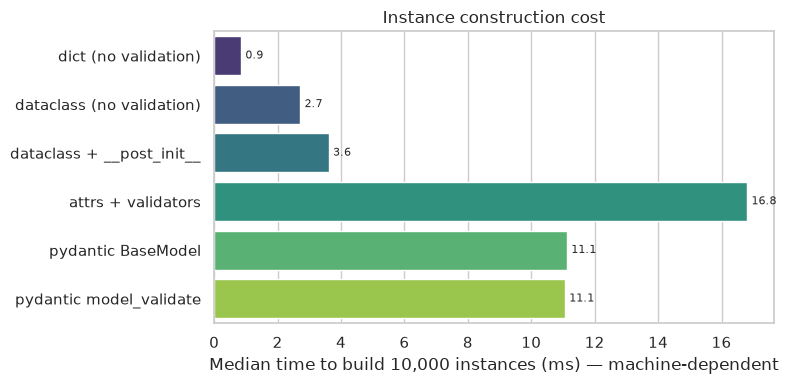

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=bench_df, y="approach", x="median_ms_10k", hue="approach", palette="viridis", legend=False, ax=ax)
ax.set_xlabel("Median time to build 10,000 instances (ms) — machine-dependent")
ax.set_ylabel("")
ax.set_title("Instance construction cost")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

### 4.2 Tabela comparativa de recursos

**Leitura dos resultados:** validação tem custo. Pydantic v2 costuma ficar na mesma ordem de grandeza de `attrs` com validadores, mas oferece muito mais (coerção, JSON, schema, erros estruturados). Para objetos internos já confiáveis, uma `dataclass` simples basta; na **fronteira** do sistema (CSV, API, formulário de professor), validação completa compensa.

In [25]:
features = pd.DataFrame(
    {
        "dataclasses": ["stdlib", "manual (__post_init__)", "no", "manual", "asdict()", "no", "frozen=True", "slots=True", "inheritance"],
        "attrs": ["external", "declarative validators", "converters", "on init + setattr (@define)", "attrs.asdict()", "no (via cattrs)", "@frozen", "default in @define", "inheritance"],
        "pydantic v2": ["external", "Field + validators", "automatic (lax mode)", "on init (validate_assignment opt.)", "model_dump()/model_dump_json()", "model_json_schema()", "frozen=True config", "n/a (Rust core)", "inheritance + nested"],
    },
    index=["Installation", "Validation", "Type coercion", "When checks run", "Serialization",
           "JSON Schema", "Immutability", "Slots/memory", "Composition"],
)
features.index.name = "feature"
features

,dataclasses,attrs,pydantic v2
feature,,,
Installation,stdlib,external,external
Validation,manual (__post_init__),declarative validators,Field + validators
Type coercion,no,converters,automatic (lax mode)
When checks run,manual,on init + setattr (@define),on init (validate_assignment opt.)
Serialization,asdict(),attrs.asdict(),model_dump()/model_dump_json()
JSON Schema,no,no (via cattrs),model_json_schema()
Immutability,frozen=True,@frozen,frozen=True config
Slots/memory,slots=True,default in @define,n/a (Rust core)
Composition,inheritance,inheritance,inheritance + nested


## Seção 5 — Pipeline real de DS com Pydantic

### 5.1 `MLDatasetConfig`: configuração validada de um experimento

Configurações erradas (ex.: `test_size=1.5`, modelo com nome errado) costumam falhar só no meio do treino. Validando a configuração **antes**, o pipeline falha cedo e com mensagem clara. `frozen=True` impede alterações acidentais durante a execução.

In [26]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score


class MLDatasetConfig(BaseModel):
    """Validated, immutable configuration for a tabular classification run."""
    model_config = ConfigDict(frozen=True, extra="forbid")

    dataset: Literal["iris"] = "iris"
    model_name: Literal["logreg", "random_forest", "knn"] = "logreg"
    test_size: float = Field(default=0.25, gt=0.05, lt=0.5)
    random_state: int = Field(default=42, ge=0)
    cv_folds: int = Field(default=5, ge=2, le=10)
    scale_features: bool = True
    hyperparams: dict[str, float | int | str] = Field(default_factory=dict)

    @model_validator(mode="after")
    def check_hyperparams(self):
        allowed = {"logreg": {"C", "max_iter"}, "random_forest": {"n_estimators", "max_depth"},
                   "knn": {"n_neighbors"}}[self.model_name]
        unknown = set(self.hyperparams) - allowed
        if unknown:
            raise ValueError(f"hyperparams {sorted(unknown)} not valid for {self.model_name}")
        return self


cfg = MLDatasetConfig.model_validate({"model_name": "logreg", "hyperparams": {"C": 1.0, "max_iter": 500}})
print(cfg.model_dump_json())

for bad in [{"test_size": 1.5}, {"model_name": "svm"}, {"model_name": "knn", "hyperparams": {"C": 1}}, {"cv": 5}]:
    try:
        MLDatasetConfig.model_validate(bad)
    except ValidationError as exc:
        print(f"{str(bad):45} -> {exc.errors()[0]['msg']}")

{"dataset":"iris","model_name":"logreg","test_size":0.25,"random_state":42,"cv_folds":5,"scale_features":true,"hyperparams":{"C":1.0,"max_iter":500}}
{'test_size': 1.5}                            -> Input should be less than 0.5
{'model_name': 'svm'}                         -> Input should be 'logreg', 'random_forest' or 'knn'
{'model_name': 'knn', 'hyperparams': {'C': 1}} -> Value error, hyperparams ['C'] not valid for knn
{'cv': 5}                                     -> Extra inputs are not permitted


### 5.2 `ModelResult` e execução do pipeline com `load_iris` (scikit-learn)

O resultado do treino também vira um modelo Pydantic: métricas com faixas `[0, 1]`, a configuração usada **aninhada** e um timestamp. Assim cada experimento fica **auto-documentado** e serializável em JSON (um "mini experiment tracker").

In [27]:
from datetime import datetime, timezone


class ModelResult(BaseModel):
    """Training/evaluation results bound to the exact config that produced them."""
    config: MLDatasetConfig
    n_train: int = Field(gt=0)
    n_test: int = Field(gt=0)
    test_accuracy: float = Field(ge=0, le=1)
    test_f1_macro: float = Field(ge=0, le=1)
    cv_mean: float = Field(ge=0, le=1)
    cv_std: float = Field(ge=0)
    fit_seconds: float = Field(ge=0)
    created_at: datetime = Field(default_factory=lambda: datetime.now(timezone.utc))


def build_estimator(cfg: MLDatasetConfig):
    """Instantiate the sklearn estimator described by the config."""
    registry = {"logreg": LogisticRegression, "random_forest": RandomForestClassifier,
                "knn": KNeighborsClassifier}
    params = dict(cfg.hyperparams)
    if cfg.model_name in {"logreg", "random_forest"}:
        params["random_state"] = cfg.random_state
    est = registry[cfg.model_name](**params)
    return make_pipeline(StandardScaler(), est) if cfg.scale_features else est


def run_pipeline(cfg: MLDatasetConfig) -> ModelResult:
    """Load data, split, cross-validate on train, fit and evaluate on test."""
    X, y = load_iris(return_X_y=True)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=cfg.test_size,
                                              random_state=cfg.random_state, stratify=y)
    est = build_estimator(cfg)
    cv = cross_val_score(est, X_tr, y_tr, cv=cfg.cv_folds)
    t0 = time.perf_counter()
    est.fit(X_tr, y_tr)
    fit_s = time.perf_counter() - t0
    pred = est.predict(X_te)
    return ModelResult(config=cfg, n_train=len(X_tr), n_test=len(X_te),
                       test_accuracy=accuracy_score(y_te, pred),
                       test_f1_macro=f1_score(y_te, pred, average="macro"),
                       cv_mean=cv.mean(), cv_std=cv.std(), fit_seconds=fit_s)


result = run_pipeline(cfg)
print(result.model_dump_json(indent=2, exclude={"config": {"hyperparams"}}))

{
  "config": {
    "dataset": "iris",
    "model_name": "logreg",
    "test_size": 0.25,
    "random_state": 42,
    "cv_folds": 5,
    "scale_features": true
  },
  "n_train": 112,
  "n_test": 38,
  "test_accuracy": 0.9210526315789473,
  "test_f1_macro": 0.9229629629629629,
  "cv_mean": 0.9640316205533598,
  "cv_std": 0.03391847897695643,
  "fit_seconds": 0.003050394356250763,
  "created_at": "2026-11-20T00:36:15.261362Z"
}


In [28]:
configs = [
    {"model_name": "logreg", "hyperparams": {"C": 1.0, "max_iter": 500}},
    {"model_name": "random_forest", "hyperparams": {"n_estimators": 200, "max_depth": 4}, "scale_features": False},
    {"model_name": "knn", "hyperparams": {"n_neighbors": 5}},
]
results_list = [run_pipeline(MLDatasetConfig.model_validate(c)) for c in configs]

summary = pd.DataFrame([
    {"model": r.config.model_name, "cv_mean": r.cv_mean, "cv_std": r.cv_std,
     "test_accuracy": r.test_accuracy, "test_f1_macro": r.test_f1_macro}
    for r in results_list
]).round(3)

# Results persist as JSON Lines and reload with full validation
jsonl = "\n".join(r.model_dump_json() for r in results_list)
reloaded = [ModelResult.model_validate_json(line) for line in jsonl.splitlines()]
print("Reloaded results:", len(reloaded), "| types:", {type(r).__name__ for r in reloaded})
summary

Reloaded results: 3 | types: {'ModelResult'}


,model,cv_mean,cv_std,test_accuracy,test_f1_macro
0,logreg,0.964,0.034,0.921,0.923
1,random_forest,0.946,0.034,0.895,0.897
2,knn,0.946,0.034,0.921,0.922


⚠️ **Interpretação honesta:** o iris é pequeno e fácil; um único *split* de 38 amostras de teste não permite ranquear modelos. O objetivo aqui é mostrar o **contrato de dados** do experimento (config → resultado validado), não escolher o melhor classificador.

## Seção 6 — Exemplo aplicado de NLP: vocabulário com faixas inspiradas no CEFR

### 6.1 Construindo o vocabulário a partir de um corpus real (NLTK Brown Corpus)

Não existe uma lista CEFR oficial livre embutida no Python. Para usar **apenas dados reais**, derivo um vocabulário do **Brown Corpus** (1,16 milhão de tokens, inglês americano escrito, 15 gêneros) e atribuo **faixas inspiradas no CEFR por frequência no próprio corpus** (palavras mais frequentes → faixas "mais baixas").

⚠️ **Limitação importante:** essas faixas são uma **heurística de frequência**, não níveis CEFR oficiais (como os do English Vocabulary Profile). Frequência é só um dos fatores de dificuldade lexical. Além disso, o campo `lemma` guarda **formas de palavra** em minúsculas (não lematizadas: `fires` e `fire` são entradas distintas).

In [29]:
import nltk

nltk.download("brown", quiet=True)
from nltk.corpus import brown

tokens = [w.lower() for w in brown.words() if w.isalpha()]
freq = Counter(tokens)
genre_presence = Counter()
for cat in brown.categories():
    genre_presence.update({w.lower() for w in brown.words(categories=cat) if w.isalpha()})

vocab = (pd.DataFrame(freq.most_common(6000), columns=["lemma", "frequency"])
         .assign(rank=lambda d: np.arange(1, len(d) + 1)))
vocab["n_genres"] = vocab["lemma"].map(genre_presence)
vocab["per_million"] = (vocab["frequency"] / len(tokens) * 1e6).round(1)

# Frequency-rank bands (CEFR-inspired heuristic, NOT official CEFR levels)
band_edges = [0, 500, 1000, 2000, 3000, 4500, 6000]
vocab["cefr_band"] = pd.cut(vocab["rank"], bins=band_edges, labels=list(CEFR_LEVELS)).astype(str)
print(f"Tokens: {len(tokens):,} | types: {len(freq):,} | vocabulary kept: {len(vocab):,}")
vocab.sample(6, random_state=21)

Tokens: 981,716 | types: 40,234 | vocabulary kept: 6,000


,lemma,frequency,rank,n_genres,per_million,cefr_band
1289,neck,81,1290,11,82.5,B1
242,among,370,243,15,376.9,A1
4996,rourke,19,4997,1,19.4,C2
5248,fires,17,5249,7,17.3,C2
2715,deeply,39,2716,13,39.7,B2
3332,dancers,31,3333,8,31.6,C1


### 6.2 O modelo `CEFRVocabularyEntry`

Regras de validação:
- `lemma`: apenas letras minúsculas (regex), 1–30 caracteres;
- `cefr_band`: um dos seis rótulos;
- `frequency > 0`, `n_genres ∈ [1, 15]`;
- **regra de consistência**: o `rank` deve cair dentro do intervalo da faixa declarada (`model_validator`);
- `computed_field` para o comprimento da palavra.

In [30]:
BAND_RANGES: dict[str, tuple[int, int]] = {
    lvl: (lo + 1, hi) for lvl, lo, hi in zip(CEFR_LEVELS, band_edges[:-1], band_edges[1:])
}


class CEFRVocabularyEntry(BaseModel):
    """Corpus-derived vocabulary entry with a frequency-based CEFR-inspired band."""
    model_config = ConfigDict(frozen=True)

    lemma: str = Field(pattern=r"^[a-z]+$", min_length=1, max_length=30)
    cefr_band: CEFRLevel
    frequency: int = Field(gt=0)
    rank: int = Field(gt=0)
    n_genres: int = Field(ge=1, le=15)
    per_million: float = Field(gt=0)

    @model_validator(mode="after")
    def rank_matches_band(self):
        lo, hi = BAND_RANGES[self.cefr_band]
        if not lo <= self.rank <= hi:
            raise ValueError(f"rank {self.rank} outside band {self.cefr_band} range {lo}-{hi}")
        return self

    @computed_field
    @property
    def word_length(self) -> int:
        return len(self.lemma)


print(BAND_RANGES)
print(CEFRVocabularyEntry.model_validate(vocab.iloc[0].to_dict()))

{'A1': (1, 500), 'A2': (501, 1000), 'B1': (1001, 2000), 'B2': (2001, 3000), 'C1': (3001, 4500), 'C2': (4501, 6000)}
lemma='the' cefr_band='A1' frequency=69971 rank=1 n_genres=15 per_million=71274.2 word_length=3


### 6.3 Validando o dataset de vocabulário

Primeiro valido o vocabulário real (deve passar 100%). Depois crio uma cópia com **erros sintéticos típicos** de planilhas feitas à mão — rótulo `"B3"`, lema com maiúscula/número, faixa inconsistente com o rank — e uso a mesma função `validate_dataframe` da Seção 3.

In [31]:
vocab_valid, vocab_errors = validate_dataframe(vocab, CEFRVocabularyEntry)
print(f"Real vocabulary: {len(vocab_valid)} valid / {len(vocab)} | errors: {len(vocab_errors)}")

dirty_vocab = vocab.head(20).copy()
dirty_vocab.loc[0, "cefr_band"] = "B3"
dirty_vocab.loc[1, "lemma"] = "The"
dirty_vocab.loc[2, "lemma"] = "w0rd"
dirty_vocab.loc[3, "cefr_band"] = "C2"   # rank 4 is not in the C2 band
dirty_vocab.loc[4, "n_genres"] = 0

_, dirty_errors = validate_dataframe(dirty_vocab, CEFRVocabularyEntry)
dirty_errors[["row", "field", "input", "error_type"]]

Real vocabulary: 6000 valid / 6000 | errors: 0


,row,field,input,error_type
0,0,cefr_band,B3,literal_error
1,1,lemma,The,string_pattern_mismatch
2,2,lemma,w0rd,string_pattern_mismatch
3,3,,"{'lemma': 'to', 'frequency': 26158, 'rank': 4,...",value_error
4,4,n_genres,0,greater_than_equal


### 6.4 Estatísticas por faixa e visualização com seaborn

Pergunta linguística: **palavras de faixas "mais altas" (menos frequentes) são mais longas e aparecem em menos gêneros?** Isso se relaciona à Lei da Abreviação de Zipf (palavras frequentes tendem a ser curtas) e à noção de **dispersão** lexical.

In [32]:
entries = [CEFRVocabularyEntry.model_validate(r) for r in vocab.to_dict(orient="records")]
vdf = pd.DataFrame([e.model_dump() for e in entries])
vdf["cefr_band"] = pd.Categorical(vdf["cefr_band"], categories=CEFR_LEVELS, ordered=True)

band_stats = (vdf.groupby("cefr_band", observed=True)
              .agg(n_words=("lemma", "size"),
                   mean_length=("word_length", "mean"),
                   median_per_million=("per_million", "median"),
                   mean_genres=("n_genres", "mean"),
                   all_15_genres_pct=("n_genres", lambda s: (s == 15).mean() * 100))
              .round(2))
band_stats

,n_words,mean_length,median_per_million,mean_genres,all_15_genres_pct
cefr_band,,,,,
A1,500,4.92,370.25,14.61,78.40
A2,500,6.29,134.50,13.32,30.80
B1,1000,6.57,71.30,11.58,5.60
B2,1000,7.06,43.80,9.91,0.40
C1,1500,7.19,27.50,8.11,0.07
C2,1500,7.24,17.30,6.64,0.00


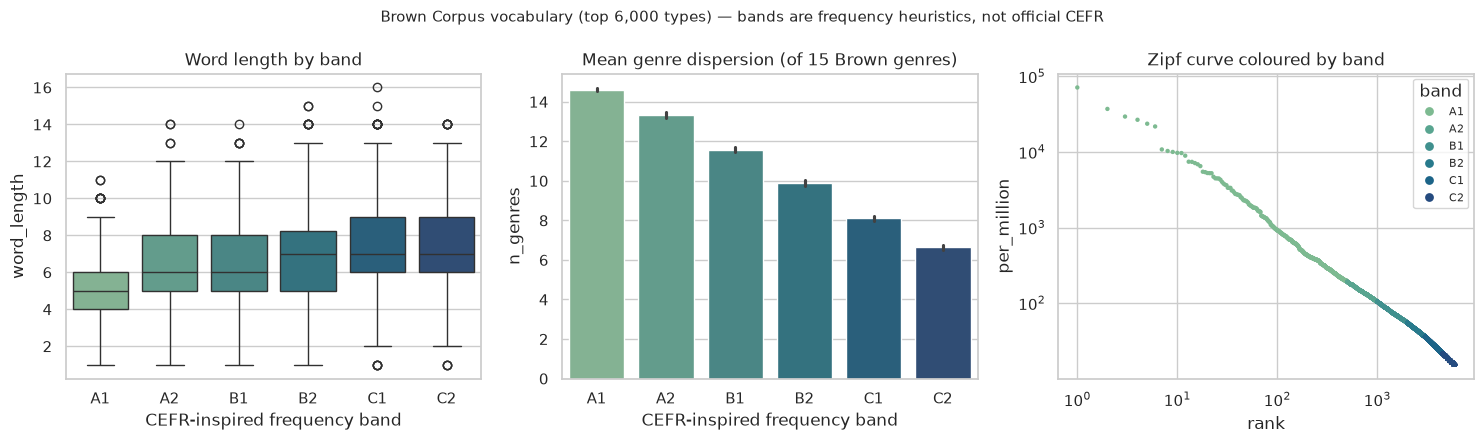

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(data=vdf, x="cefr_band", y="word_length", hue="cefr_band", palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Word length by band")
axes[0].set_xlabel("CEFR-inspired frequency band")

sns.barplot(data=vdf, x="cefr_band", y="n_genres", hue="cefr_band", palette="crest", legend=False,
            errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("Mean genre dispersion (of 15 Brown genres)")
axes[1].set_xlabel("CEFR-inspired frequency band")

sns.scatterplot(data=vdf, x="rank", y="per_million", hue="cefr_band", palette="crest", s=10,
                linewidth=0, ax=axes[2])
axes[2].set(xscale="log", yscale="log", title="Zipf curve coloured by band")
axes[2].legend(title="band", markerscale=2, fontsize=8)

fig.suptitle("Brown Corpus vocabulary (top 6,000 types) — bands are frequency heuristics, not official CEFR", fontsize=11)
plt.tight_layout()
plt.show()

In [34]:
from scipy.stats import spearmanr

rho_len, p_len = spearmanr(vdf["rank"], vdf["word_length"])
rho_gen, p_gen = spearmanr(vdf["rank"], vdf["n_genres"])
print(f"Spearman rank vs word length : rho={rho_len:.3f} (p={p_len:.1e})")
print(f"Spearman rank vs n_genres    : rho={rho_gen:.3f} (p={p_gen:.1e})")
print("\nExamples per band:")
for lvl in CEFR_LEVELS:
    sample = vdf.loc[vdf["cefr_band"] == lvl, "lemma"].sample(6, random_state=1).tolist()
    print(f"  {lvl}: {', '.join(sample)}")

Spearman rank vs word length : rho=0.231 (p=2.1e-73)
Spearman rank vs n_genres    : rho=-0.764 (p=0.0e+00)

Examples per band:
  A1: above, tell, more, these, increase, gone
  A2: carried, stop, instead, cold, b, role
  B1: teachers, stories, somehow, official, bank, academic
  B2: recreation, regardless, manchester, charges, bills, multiple
  C1: bus, reporters, plaster, letting, regularly, eliminate
  C2: reveals, summary, willis, elementary, honors, failing


**Interpretação:** na execução salva, o rank de frequência teve correlação de Spearman positiva fraca com o comprimento (ρ ≈ 0,23) e negativa forte com o número de gêneros (ρ ≈ −0,76): no Brown Corpus, palavras menos frequentes tendem a ser **um pouco mais longas** e **bem menos dispersas** entre gêneros. Note também ruídos típicos de corpus (nomes próprios como `willis`, letras soltas como `b`) que uma lista pedagógica real filtraria. Isso é uma correlação no corpus (inglês americano escrito de 1961), não uma medida de dificuldade para aprendizes brasileiros — para isso seriam necessários dados de aprendizes e listas como o English Vocabulary Profile.

## Resumo e quando usar cada ferramenta

| Situação | Recomendação |
| --- | --- |
| Objetos internos, dados já confiáveis, zero dependências | `@dataclass` (com `slots=True`, `frozen=True` quando fizer sentido) |
| Validadores/conversores declarativos, classes leves, código de biblioteca | `attrs` (`@define`, `@frozen`) |
| Fronteira do sistema: CSV, APIs (FastAPI), configs, JSON, relatórios de erro | `pydantic` `BaseModel` |

**Lições do dia:**
1. Anotações de tipo **não validam nada sozinhas** — só ferramentas como `attrs`/`pydantic` (ou código manual) fazem isso.
2. **Colete erros** em vez de abortar: um relatório `linha × campo × erro` é um artefato de qualidade de dados.
3. Validação custa tempo (veja o benchmark) — aplique-a onde os dados **entram** no sistema.
4. Configs e resultados de experimentos como modelos Pydantic deixam o pipeline **reprodutível e auto-documentado**.
5. No exemplo de NLP, as faixas "CEFR" são **heurísticas de frequência** — o modelo de dados torna essa suposição explícita e verificável.

**Próximos passos:** usar estes modelos com FastAPI (validação automática de requisições, como no projeto Tino) e explorar `pandera` para validação de esquemas diretamente em DataFrames.